Upload FinBERT_VADER_Combined_Net_Sentiment.csv


Saving FinBERT_VADER_Combined_Net_Sentiment.csv to FinBERT_VADER_Combined_Net_Sentiment.csv
Upload stocks_data_clean.csv


Saving stocks_data_clean.csv to stocks_data_clean.csv
1026 rows, 2022-11-16 to 2026-10-27, 13 features
Train: 2022-11-16 to 2026-01-12 (820)
Test:  2026-01-13 to 2026-10-27 (206)

Pinball loss (lower is better):
  q=0.10: model 0.4162 | baseline 0.4180
  q=0.25: model 0.7396 | baseline 0.7263
  q=0.50: model 0.9164 | baseline 0.9079
  q=0.75: model 0.7461 | baseline 0.7433
  q=0.90: model 0.4511 | baseline 0.4511

10%-90% interval coverage: 82.5% (target 80%)
Median forecast MAE: 1.833  | naive 'tomorrow = 0' MAE: 1.809

Up/Down results (median rule):
  Accuracy: 0.490   F1: 0.639
  Confusion matrix [rows = actual down/up, cols = predicted down/up]:
[[ 8 96]
 [ 9 93]]

Baselines:
  Always predict up (training majority): 0.495
  Same direction as today: 0.539


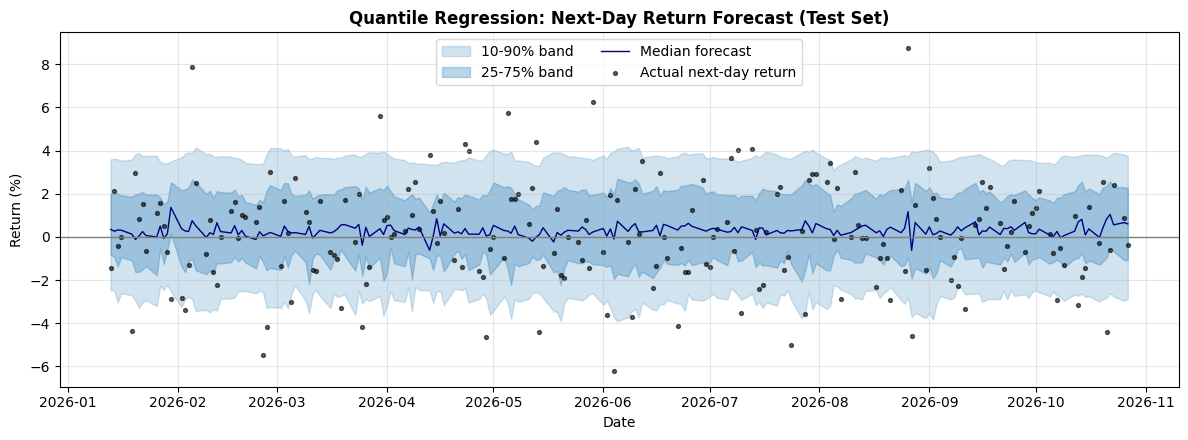

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
!pip install -q scikit-learn openpyxl

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.linear_model import QuantileRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_pinball_loss, accuracy_score, f1_score,
                             confusion_matrix, mean_absolute_error)

QUANTILES = [0.1, 0.25, 0.5, 0.75, 0.9]
TEST_FRACTION = 0.2
ALPHA = 0.01          # L1 regularization; try 0, 0.001, 0.01, 0.1
SENT_COL = "combined_net_sentiment"   # or "finbert_net_sentiment" / "vader_net_sentiment"

def upload_table(prompt):
    print(prompt)
    up = files.upload()
    name = next(iter(up))
    raw = io.BytesIO(up[name])
    return pd.read_excel(raw) if name.lower().endswith((".xlsx", ".xls")) else pd.read_csv(raw)

# ---------- 1. Upload ----------
news = upload_table("Upload FinBERT_VADER_Combined_Net_Sentiment.csv")
prices = upload_table("Upload stocks_data_clean.csv")

# ---------- 2. Daily sentiment, mapped to trading days ----------
prices["date"] = pd.to_datetime(prices["date"])
prices = prices.sort_values("date").reset_index(drop=True)

news["date"] = pd.to_datetime(news["date"], dayfirst=True).dt.normalize()   # dd-mm-yyyy
news["sent"] = news[SENT_COL]
# weekend/holiday headlines go to the next trading day
news = pd.merge_asof(news.sort_values("date"), prices[["date"]].rename(columns={"date": "tday"}),
                     left_on="date", right_on="tday", direction="forward").dropna(subset=["tday"])
daily = news.groupby("tday").agg(sent=("sent", "mean"), n_news=("sent", "size"))
daily.index.name = "date"

df = prices.merge(daily.reset_index(), on="date", how="left")
first_news = daily.index.min()
df = df[df["date"] >= first_news].copy()               # only periods where we have news
df[["sent", "n_news"]] = df[["sent", "n_news"]].fillna(0)

# ---------- 3. Features (all use data up to and including day t) ----------
df["ret"] = df["stock_ret"] * 100
f = pd.DataFrame({"date": df["date"]})
for k in (1, 2, 3):
    f[f"ret_lag{k}"] = df["ret"].shift(k - 1)          # lag1 = today's return
f["ret_5d_mean"] = df["ret"].rolling(5).mean()
f["vol_5d"] = df["ret"].rolling(5).std()
f["ma20_gap"] = (df["stock"] / df["stock"].rolling(20).mean() - 1) * 100
for c in ("gold_ret", "oil_ret", "usdinr_ret"):
    f[c] = df[c] * 100
f["sent"] = df["sent"]
f["sent_3d"] = df["sent"].rolling(3).mean()
f["sent_5d"] = df["sent"].rolling(5).mean()
f["log_n_news"] = np.log1p(df["n_news"])

f["next_ret"] = df["ret"].shift(-1)                    # TARGET: tomorrow's return
f = f.dropna().reset_index(drop=True)
features = [c for c in f.columns if c not in ("date", "next_ret")]
print(f"{len(f)} rows, {f['date'].min().date()} to {f['date'].max().date()}, {len(features)} features")

# ---------- 4. Time-based split (no shuffling) ----------
cut = int(len(f) * (1 - TEST_FRACTION))
train, test = f.iloc[:cut], f.iloc[cut:]
Xtr, ytr = train[features], train["next_ret"]
Xte, yte = test[features], test["next_ret"]
print(f"Train: {train['date'].min().date()} to {train['date'].max().date()} ({len(train)})")
print(f"Test:  {test['date'].min().date()} to {test['date'].max().date()} ({len(test)})")

# ---------- 5. Fit one model per quantile ----------
preds = {}
for q in QUANTILES:
    model = make_pipeline(StandardScaler(),
                          QuantileRegressor(quantile=q, alpha=ALPHA, solver="highs"))
    model.fit(Xtr, ytr)
    preds[q] = model.predict(Xte)
P = np.sort(np.column_stack([preds[q] for q in QUANTILES]), axis=1)   # fix quantile crossing
pred_df = pd.DataFrame(P, columns=[f"q{int(q*100)}" for q in QUANTILES], index=test.index)

# ---------- 6. Quantile evaluation vs baseline (training-set quantiles) ----------
print("\nPinball loss (lower is better):")
for i, q in enumerate(QUANTILES):
    model_loss = mean_pinball_loss(yte, P[:, i], alpha=q)
    base_loss = mean_pinball_loss(yte, np.full(len(yte), np.quantile(ytr, q)), alpha=q)
    print(f"  q={q:.2f}: model {model_loss:.4f} | baseline {base_loss:.4f}")
cov = ((yte >= P[:, 0]) & (yte <= P[:, -1])).mean()
print(f"\n{QUANTILES[0]:.0%}-{QUANTILES[-1]:.0%} interval coverage: {cov:.1%} (target {QUANTILES[-1]-QUANTILES[0]:.0%})")
print(f"Median forecast MAE: {mean_absolute_error(yte, P[:, 2]):.3f}  "
      f"| naive 'tomorrow = 0' MAE: {mean_absolute_error(yte, np.zeros(len(yte))):.3f}")

# ---------- 7. Up/Down classification ----------
y_true = (yte > 0).astype(int).values
y_pred = (P[:, 2] > 0).astype(int)                      # up if median forecast > 0

# optional: P(up) from where the forecast quantiles cross zero
tau0 = np.array([np.interp(0, row, QUANTILES, left=0.0, right=1.0) for row in P])
p_up = 1 - tau0

print("\nUp/Down results (median rule):")
print(f"  Accuracy: {accuracy_score(y_true, y_pred):.3f}   F1: {f1_score(y_true, y_pred):.3f}")
print("  Confusion matrix [rows = actual down/up, cols = predicted down/up]:")
print(confusion_matrix(y_true, y_pred))

majority = int(ytr.gt(0).mean() >= 0.5)
same_dir = (test["ret_lag1"] > 0).astype(int).values     # "same direction as today"
print("\nBaselines:")
print(f"  Always predict {'up' if majority else 'down'} (training majority): "
      f"{accuracy_score(y_true, np.full(len(y_true), majority)):.3f}")
print(f"  Same direction as today: {accuracy_score(y_true, same_dir):.3f}")

# ---------- 8. Plot: forecast band vs actual (test set) ----------
fig, ax = plt.subplots(figsize=(12, 4.5))
d = test["date"].values
ax.fill_between(d, pred_df["q10"], pred_df["q90"], alpha=0.2, color="tab:blue", label="10-90% band")
ax.fill_between(d, pred_df["q25"], pred_df["q75"], alpha=0.3, color="tab:blue", label="25-75% band")
ax.plot(d, pred_df["q50"], color="navy", lw=1, label="Median forecast")
ax.scatter(d, yte, s=8, color="black", alpha=0.6, label="Actual next-day return")
ax.axhline(0, color="gray", lw=1)
ax.set_title("Quantile Regression: Next-Day Return Forecast (Test Set)", fontweight="bold")
ax.set_xlabel("Date"); ax.set_ylabel("Return (%)"); ax.legend(ncol=2); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("quantile_forecast.png", dpi=200); plt.show()

out = test[["date", "next_ret"]].join(pred_df)
out["p_up"] = p_up; out["pred_dir"] = np.where(y_pred == 1, "Up", "Down")
out.to_csv("quantile_predictions.csv", index=False)
files.download("quantile_forecast.png"); files.download("quantile_predictions.csv")

Test rows: 206 | zero-return days: 7 | actual up: 49.5% | predicted up: 91.7%
Test period: 2026-01-13 to 2026-10-27

Confusion matrix [rows = actual Down/Up, cols = predicted Down/Up]
[[ 8 96]
 [ 9 93]]


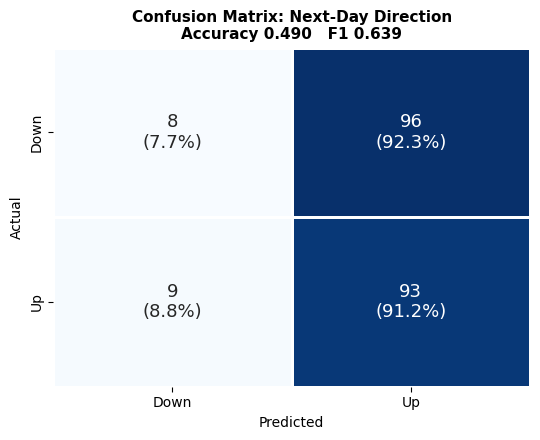

In [2]:
import numpy as np, seaborn as sns, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score

y_ret = np.asarray(yte)          # actual next-day return (test set)
y_fc  = np.asarray(P[:, 2])      # median (q50) forecast

def direction_cm(y_ret, y_fc, drop_zero=False):
    if drop_zero:
        k = y_ret != 0
        y_ret, y_fc = y_ret[k], y_fc[k]
    t = (y_ret > 0).astype(int)                      # 1 = Up, 0 = Down
    p = (y_fc > 0).astype(int)
    return confusion_matrix(t, p, labels=[0, 1]), t, p

# ---- diagnostics ----
print(f"Test rows: {len(y_ret)} | zero-return days: {(y_ret == 0).sum()} "
      f"| actual up: {(y_ret > 0).mean():.1%} | predicted up: {(y_fc > 0).mean():.1%}")
print(f"Test period: {test['date'].min().date()} to {test['date'].max().date()}")

# ---- print and plot from the SAME matrix ----
DROP_ZERO = False        # True = ignore days with exactly 0% return
cm, t, p = direction_cm(y_ret, y_fc, DROP_ZERO)
print("\nConfusion matrix [rows = actual Down/Up, cols = predicted Down/Up]")
print(cm)

pct = cm / cm.sum(axis=1, keepdims=True) * 100
annot = np.array([[f"{cm[i, j]}\n({pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, linewidths=1, linecolor="white",
            xticklabels=["Down", "Up"], yticklabels=["Down", "Up"], annot_kws={"size": 13}, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix: Next-Day Direction\nAccuracy {accuracy_score(t, p):.3f}   "
             f"F1 {f1_score(t, p):.3f}", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=200); plt.show()

=== Next-day % change ===
Quantile reg  RMSE 2.3495 | MAE 1.8327 | R2 0.0019
Predict 0     RMSE 2.3540 | MAE 1.8089 | R2 -0.0020
Train median  RMSE 2.3544 | MAE 1.8158 | R2 -0.0023
Pinball q=0.5: model 0.9164 | baseline 0.9079
10-90% band coverage: 82.5% (target 80%)
Direction accuracy: 0.508 (always-up: 0.513)

=== Closing price (USD) ===
Quantile reg   RMSE 4.782 | R2 0.9254
Tomorrow=today RMSE 4.777 | R2 0.9255


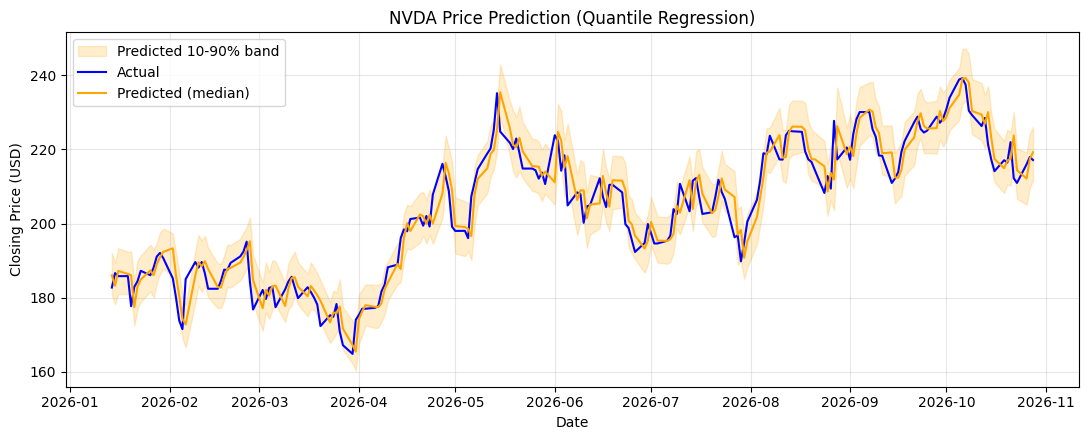

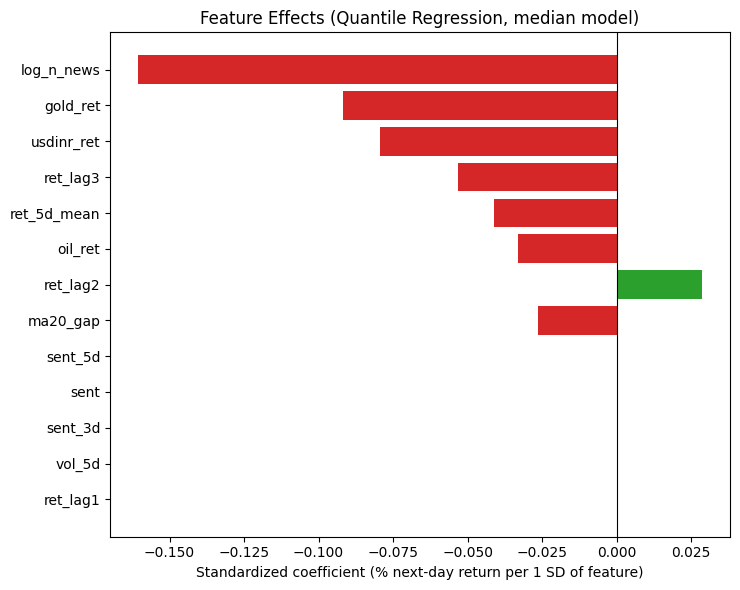

Features set to zero by the L1 penalty: 5 of 13

=== Walk-forward check ===
  fold  mae_model  mae_baseline  dir_acc
    1     1.8763        1.8803   0.5793
    2     2.5714        2.5731   0.5241
    3     2.4386        2.4456   0.5305
    4     1.5922        1.5879   0.5361
    5     1.7982        1.8037   0.5422


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import QuantileRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_pinball_loss

FEATURES = features                            # feature list from the main script
ALPHA = globals().get("best_alpha", ALPHA)     # uses your tuned alpha if you have one, else the main script's ALPHA
rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))
make_qr = lambda q: make_pipeline(StandardScaler(),
                                  QuantileRegressor(quantile=q, alpha=ALPHA, solver="highs"))

# ---- fit 10% / 50% / 90% models on the training set ----
qm = {q: make_qr(q).fit(train[FEATURES], train["next_ret"]) for q in (0.1, 0.5, 0.9)}
P3 = np.sort(np.column_stack([qm[q].predict(test[FEATURES]) for q in (0.1, 0.5, 0.9)]), axis=1)
q10, pred, q90 = P3[:, 0], P3[:, 1], P3[:, 2]
y = test["next_ret"].values

# ---- metrics vs baselines (next-day % change) ----
print("=== Next-day % change ===")
print(f"Quantile reg  RMSE {rmse(y, pred):.4f} | MAE {mean_absolute_error(y, pred):.4f} | R2 {r2_score(y, pred):.4f}")
for name, b in (("Predict 0", np.zeros(len(y))), ("Train median", np.full(len(y), train["next_ret"].median()))):
    print(f"{name:<13} RMSE {rmse(y, b):.4f} | MAE {mean_absolute_error(y, b):.4f} | R2 {r2_score(y, b):.4f}")
print(f"Pinball q=0.5: model {mean_pinball_loss(y, pred, alpha=0.5):.4f} | "
      f"baseline {mean_pinball_loss(y, np.full(len(y), train['next_ret'].median()), alpha=0.5):.4f}")
print(f"10-90% band coverage: {((y >= q10) & (y <= q90)).mean():.1%} (target 80%)")
nz = y != 0
print(f"Direction accuracy: {(np.sign(pred[nz]) == np.sign(y[nz])).mean():.3f} "
      f"(always-up: {(y[nz] > 0).mean():.3f})")

# ---- convert to a price chart (looks up today's close and tomorrow's date from df) ----
px = df.set_index("date")["stock"]
nxt = pd.Series(df["date"].shift(-1).values, index=df["date"])
close = px.reindex(test["date"]).values
next_date = nxt.reindex(test["date"]).values
actual_px, pred_px = close * (1 + y / 100), close * (1 + pred / 100)

print("\n=== Closing price (USD) ===")
print(f"Quantile reg   RMSE {rmse(actual_px, pred_px):.3f} | R2 {r2_score(actual_px, pred_px):.4f}")
print(f"Tomorrow=today RMSE {rmse(actual_px, close):.3f} | R2 {r2_score(actual_px, close):.4f}")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.fill_between(next_date, close * (1 + q10 / 100), close * (1 + q90 / 100),
                color="orange", alpha=0.2, label="Predicted 10-90% band")
ax.plot(next_date, actual_px, color="blue", label="Actual")
ax.plot(next_date, pred_px, color="orange", label="Predicted (median)")
ax.set_title("NVDA Price Prediction (Quantile Regression)")
ax.set_xlabel("Date"); ax.set_ylabel("Closing Price (USD)"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig("price_prediction_qr.png", dpi=200); plt.show()

# ---- feature importance = standardized coefficients of the median model ----
coef = qm[0.5].named_steps["quantileregressor"].coef_
imp = pd.DataFrame({"Feature": FEATURES, "Coef": coef}).assign(abs=lambda d: d.Coef.abs()).sort_values("abs")
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh(imp["Feature"], imp["Coef"], color=np.where(imp["Coef"] >= 0, "tab:green", "tab:red"))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Feature Effects (Quantile Regression, median model)")
ax.set_xlabel("Standardized coefficient (% next-day return per 1 SD of feature)")
plt.tight_layout(); plt.savefig("feature_importance_qr.png", dpi=200); plt.show()
print(f"Features set to zero by the L1 penalty: {int((coef == 0).sum())} of {len(coef)}")

# ---- walk-forward verification ----
all_data = pd.concat([train, test])
rows = []
for i, (tr, te) in enumerate(TimeSeriesSplit(n_splits=5).split(all_data), 1):
    m = make_qr(0.5).fit(all_data.iloc[tr][FEATURES], all_data.iloc[tr]["next_ret"])
    yt, p = all_data.iloc[te]["next_ret"].values, m.predict(all_data.iloc[te][FEATURES])
    base = np.full(len(yt), all_data.iloc[tr]["next_ret"].median()); k = yt != 0
    rows.append({"fold": i, "mae_model": mean_absolute_error(yt, p),
                 "mae_baseline": mean_absolute_error(yt, base),
                 "dir_acc": (np.sign(p[k]) == np.sign(yt[k])).mean()})
wf = pd.DataFrame(rows).round(4)
print("\n=== Walk-forward check ===\n", wf.to_string(index=False))

from google.colab import files
files.download("price_prediction_qr.png"); files.download("feature_importance_qr.png")

In [5]:
!pip install -q scikit-learn

import io
import numpy as np
import pandas as pd
from google.colab import files
from sklearn.linear_model import QuantileRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_pinball_loss, accuracy_score

QUANTILES = [0.1, 0.25, 0.5, 0.75, 0.9]
ALPHA = 0.01
SENT_COL = "combined_net_sentiment"

def upload_table(prompt):
    print(prompt)
    up = files.upload()
    name = next(iter(up))
    return pd.read_csv(io.BytesIO(up[name]))

# 1. Load data
news = upload_table("Upload FinBERT_VADER_Combined_Net_Sentiment.csv")
prices = upload_table("Upload stocks_data_clean.csv")

# 2. Daily sentiment mapped to trading days
prices["date"] = pd.to_datetime(prices["date"])
prices = prices.sort_values("date").reset_index(drop=True)
news["date"] = pd.to_datetime(news["date"], dayfirst=True).dt.normalize()
news["sent"] = news[SENT_COL]
news = pd.merge_asof(news.sort_values("date"),
                     prices[["date"]].rename(columns={"date": "tday"}),
                     left_on="date", right_on="tday", direction="forward").dropna(subset=["tday"])
daily = news.groupby("tday").agg(sent=("sent", "mean"), n_news=("sent", "size"))
daily.index.name = "date"
df = prices.merge(daily.reset_index(), on="date", how="left")
df = df[df["date"] >= daily.index.min()].copy()
df[["sent", "n_news"]] = df[["sent", "n_news"]].fillna(0)

# 3. Features and target
df["ret"] = df["stock_ret"] * 100
f = pd.DataFrame({"date": df["date"]})
for k in (1, 2, 3):
    f[f"ret_lag{k}"] = df["ret"].shift(k - 1)
f["ret_5d_mean"] = df["ret"].rolling(5).mean()
f["vol_5d"] = df["ret"].rolling(5).std()
f["ma20_gap"] = (df["stock"] / df["stock"].rolling(20).mean() - 1) * 100
for c in ("gold_ret", "oil_ret", "usdinr_ret"):
    f[c] = df[c] * 100
f["sent"] = df["sent"]
f["sent_3d"] = df["sent"].rolling(3).mean()
f["sent_5d"] = df["sent"].rolling(5).mean()
f["log_n_news"] = np.log1p(df["n_news"])
f["next_ret"] = df["ret"].shift(-1)               # target: tomorrow's return
f = f.dropna().reset_index(drop=True)
FEATURES = [c for c in f.columns if c not in ("date", "next_ret")]

# 4. Time-based train/test split
cut = int(len(f) * 0.8)
train, test = f.iloc[:cut], f.iloc[cut:]
Xtr, ytr, Xte, yte = train[FEATURES], train["next_ret"], test[FEATURES], test["next_ret"]

# 5. Train one quantile regressor per quantile
models = {q: make_pipeline(StandardScaler(),
                           QuantileRegressor(quantile=q, alpha=ALPHA, solver="highs")).fit(Xtr, ytr)
          for q in QUANTILES}
P = np.sort(np.column_stack([models[q].predict(Xte) for q in QUANTILES]), axis=1)

# 6. Evaluate
for i, q in enumerate(QUANTILES):
    base = np.full(len(yte), np.quantile(ytr, q))
    print(f"q={q}: model {mean_pinball_loss(yte, P[:, i], alpha=q):.4f} | "
          f"baseline {mean_pinball_loss(yte, base, alpha=q):.4f}")
print(f"10-90% coverage: {((yte >= P[:, 0]) & (yte <= P[:, -1])).mean():.1%} (target 80%)")
print(f"Up/Down accuracy: {accuracy_score(yte > 0, P[:, 2] > 0):.3f}")

Upload FinBERT_VADER_Combined_Net_Sentiment.csv


Saving FinBERT_VADER_Combined_Net_Sentiment.csv to FinBERT_VADER_Combined_Net_Sentiment (2).csv
Upload stocks_data_clean.csv


Saving stocks_data_clean.csv to stocks_data_clean (1).csv
q=0.1: model 0.4162 | baseline 0.4180
q=0.25: model 0.7396 | baseline 0.7263
q=0.5: model 0.9164 | baseline 0.9079
q=0.75: model 0.7461 | baseline 0.7433
q=0.9: model 0.4511 | baseline 0.4511
10-90% coverage: 82.5% (target 80%)
Up/Down accuracy: 0.490
